In [335]:
!pip install -U kaleido

In [336]:
# Importando as bibliotecas para a análise e construção dos gráficos
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import plotly.graph_objects as go
import numpy as np
import datetime

In [368]:
# Importando os dados e visualizando
perfil_entrevistados = pd.read_csv('Respostas 1.csv',sep=';')
perfil_entrevistados.head()

,regiao,faixa_etaria,sexo,raca,escolaridade,diabetes,hipertensao,doenca_respiratoria,doenca_cardiaca,depressao,cancer,situacao_trabalho,entrevistados
0,Norte,Adulto,Homem,Parda,Nível Médio,Sim,Sim,Não,Não,Não,Não,Trabalho Informal,14
1,Centro-Oeste,Adulto,Mulher,Branca,Nível Superior,Sim,Não,Não,Sim,Não,Não,NaN,1
2,Norte,Adulto,Mulher,Parda,Nível Médio,Não,Sim,Não,Não,Não,Sim,Trabalho Formal,2
3,Sudeste,Adulto,Mulher,Branca,Nível Básico,Sim,Não,Sim,Não,Sim,Não,NaN,6
4,Centro-Oeste,Idoso,Mulher,Parda,Nível Médio,Sim,Não,Não,Não,Não,Não,Trabalho Informal,1


In [338]:
perfil_entrevistados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19198 entries, 0 to 19197
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   regiao               19198 non-null  object
 1   faixa_etaria         19198 non-null  object
 2   sexo                 19198 non-null  object
 3   raca                 19198 non-null  object
 4   escolaridade         19198 non-null  object
 5   diabetes             19198 non-null  object
 6   hipertensao          19198 non-null  object
 7   doenca_respiratoria  19198 non-null  object
 8   doenca_cardiaca      19198 non-null  object
 9   depressao            19198 non-null  object
 10  cancer               19198 non-null  object
 11  situacao_trabalho    10728 non-null  object
 12  entrevistados        19198 non-null  int64 
dtypes: int64(1), object(12)
memory usage: 1.9+ MB


In [339]:
# Verficando o total de entrevistados
print(f'Total de entrevistados: {perfil_entrevistados["entrevistados"].sum()}')

Total de entrevistados: 1538445


In [371]:
# Verificando o total de entrevistados por faixa etária
faixa_etaria = perfil_entrevistados.groupby('faixa_etaria')['entrevistados'].sum().reset_index()

# Calculando o total geral
total_geral = faixa_etaria['entrevistados'].sum()

# Adicionando a coluna de percentual
faixa_etaria['percentual'] = (faixa_etaria['entrevistados'] / total_geral) * 100

# Arredondando os percentuais (opcional)
faixa_etaria['percentual'] = faixa_etaria['percentual'].round(2)

# Visualizando o resultado
faixa_etaria

,faixa_etaria,entrevistados,percentual
0,Adolescente,140161,9.11
1,Adulto,881999,57.33
2,Criança,248177,16.13
3,Idoso,268108,17.43


In [341]:
# Definindo as cores para o sexo
cores = {
    'Homem': '#7A9CA8',
    'Mulher': '#B76E79'
}

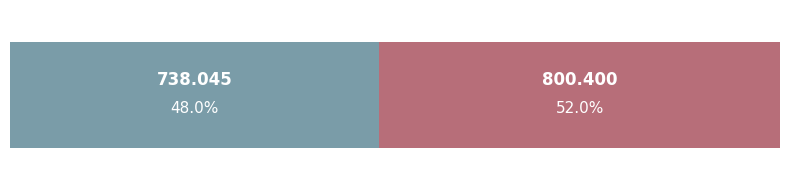

In [342]:
## Criando o gráfico da distribuição pelo sexo
# Corrigir espaços e valores ausentes
perfil_entrevistados['sexo'] = perfil_entrevistados['sexo'].str.strip()
perfil_entrevistados = perfil_entrevistados.dropna(subset=['sexo'])

# Agrupar e somar entrevistados por sexo
df_sexo = perfil_entrevistados.groupby('sexo')['entrevistados'].sum().reset_index()

# Calcular percentual para 100% empilhado
total = df_sexo['entrevistados'].sum()
df_sexo['percentual'] = df_sexo['entrevistados'] / total

# Mapear cores específicas (ajustado para 'Homem' e 'Mulher')
df_sexo['cor'] = df_sexo['sexo'].map(cores)

# Criar figura e eixo com fundo transparente
fig, ax = plt.subplots(figsize=(8, 2), facecolor='none')

# Variável para controle da posição horizontal da pilha
left = 0

for _, row in df_sexo.iterrows():
    if pd.isna(row['cor']):
        continue  # pula se não houver cor definida

    # Barra horizontal
    ax.barh(0, row['percentual'], left=left, color=row['cor'], height=0.5)

    # Texto: quantidade com ponto como separador de milhar
    ax.text(left + row['percentual']/2, 0.03,
            f"{int(row['entrevistados']):,}".replace(",", "."),
            ha='center', va='bottom', fontsize=12, fontweight='bold', color='white')

    # Texto: percentual abaixo
    ax.text(left + row['percentual']/2, -0.03,
            f"{row['percentual']*100:.1f}%",
            ha='center', va='top', fontsize=11, color='white')

    left += row['percentual']

# Limpar visual do gráfico
ax.set_xlim(0, 1)
ax.set_ylim(-0.4, 0.4)
ax.axis('off')


plt.tight_layout()
plt.savefig('distruibuição.png', transparent=True, bbox_inches='tight', dpi=600)
plt.show()


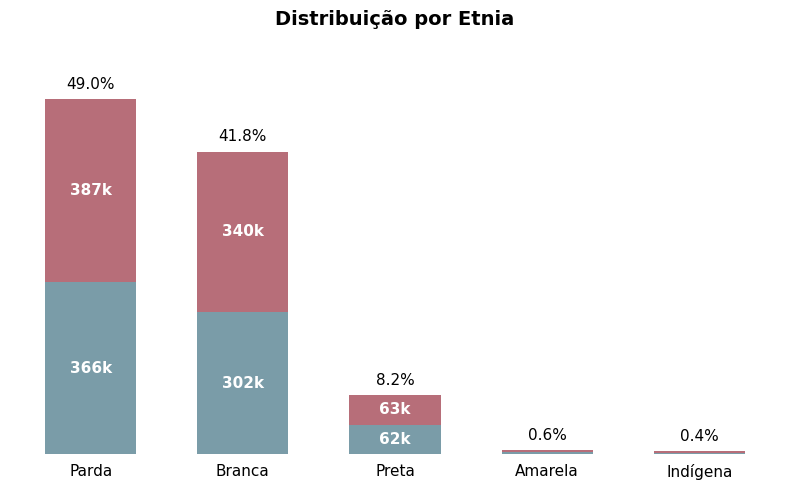

In [343]:
# Agrupamento por raça e sexo
df_raca_sexo = perfil_entrevistados.groupby(['raca', 'sexo'])['entrevistados'].sum().reset_index()

# Filtrar para remover a raça "Ignorado"
df_raca_sexo = df_raca_sexo[df_raca_sexo['raca'] != 'Ignorado']

# Soma total por raça (para ordenação e percentual final)
totais_raca = df_raca_sexo.groupby('raca')['entrevistados'].sum().reset_index(name='total')
total_geral = totais_raca['total'].sum()
totais_raca['percentual_total'] = totais_raca['total'] / total_geral

# Mesclar total de cada raça de volta no df principal
df_raca_sexo = pd.merge(df_raca_sexo, totais_raca, on='raca')

# Ordenar raças do maior para o menor total
df_raca_sexo['raca'] = pd.Categorical(df_raca_sexo['raca'],
    categories=totais_raca.sort_values('total', ascending=False)['raca'], ordered=True)

# Mapeamento de cores
df_raca_sexo['cor'] = df_raca_sexo['sexo'].map(cores)

fig, ax = plt.subplots(figsize=(8, 5), facecolor='none')

racas = df_raca_sexo['raca'].cat.categories.tolist()
x = range(len(racas))

# Inicializar a base das barras empilhadas (zero)
bottoms = [0] * len(racas)

# Vamos plotar cada sexo, acumulando em bottom
for sexo in ['Homem', 'Mulher']:
    vals = []
    for raca in racas:
        linha = df_raca_sexo[(df_raca_sexo['raca'] == raca) & (df_raca_sexo['sexo'] == sexo)]
        if not linha.empty:
            vals.append(linha['entrevistados'].values[0])
        else:
            vals.append(0)

    bars = ax.bar(x, vals, bottom=bottoms, color=cores[sexo], width=0.6, label=sexo)

    # Colocar valores dentro da barra se couber (> 50000)
    for bar, val in zip(bars, vals):
        if val > 50_000:
            texto = f"{int(val/1000)}k"
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_y() + bar.get_height()/2,
                    texto, ha='center', va='center', fontsize=11, color='white', fontweight='bold')

    # Atualizar bottoms para empilhar
    bottoms = [bottom + val for bottom, val in zip(bottoms, vals)]

# Colocar percentual total acima da barra
for i, raca in enumerate(racas):
    total = totais_raca.loc[totais_raca['raca'] == raca, 'total'].values[0]
    perc = totais_raca.loc[totais_raca['raca'] == raca, 'percentual_total'].values[0] * 100
    ax.text(i, total + total_geral * 0.01, f"{perc:.1f}%", ha='center', va='bottom', fontsize=11)

# Ajustes visuais
ax.set_xticks(x)
ax.set_xticklabels(racas, fontsize=11)
ax.set_yticks([])
ax.set_ylim(0, max(totais_raca['total'])*1.15)

# Limpar bordas e eixos, mantendo rótulos do x
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.tick_params(left=False, bottom=False)


ax.set_title("Distribuição por Etnia", fontsize=14, weight='bold', pad=15)

plt.tight_layout()
plt.savefig('raça.png', transparent=True, bbox_inches='tight', dpi=600)
plt.show()

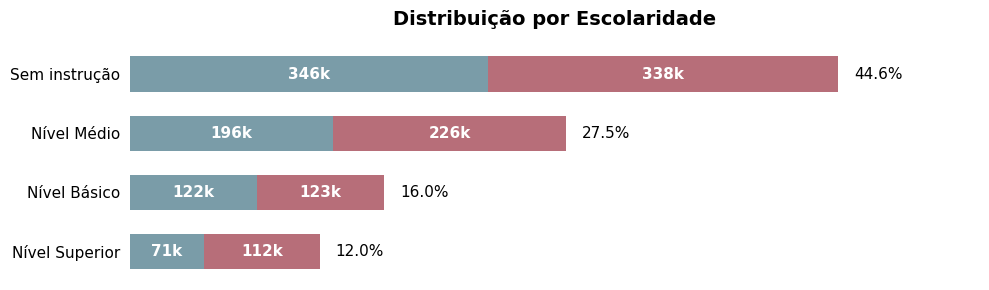

In [344]:
# Agrupamento por escolaridade e sexo
df_esc_sexo = perfil_entrevistados.groupby(['escolaridade', 'sexo'])['entrevistados'].sum().reset_index()

# Soma total por escolaridade (para ordenação e percentual final)
totais_esc = df_esc_sexo.groupby('escolaridade')['entrevistados'].sum().reset_index(name='total')
total_geral_esc = totais_esc['total'].sum()
totais_esc['percentual_total'] = totais_esc['total'] / total_geral_esc

# Mesclar total de cada escolaridade de volta no df principal
df_esc_sexo = pd.merge(df_esc_sexo, totais_esc, on='escolaridade')

# Ordenar escolaridades do maior para o menor total
df_esc_sexo['escolaridade'] = pd.Categorical(df_esc_sexo['escolaridade'],
    categories=totais_esc.sort_values('total', ascending=False)['escolaridade'], ordered=True)

# Mapeamento de cores (mesmo padrão)
df_esc_sexo['cor'] = df_esc_sexo['sexo'].map(cores)

# Plotagem
fig, ax = plt.subplots(figsize=(10, 3), facecolor='none')

# Lista de escolaridades ordenadas
escolaridades = df_esc_sexo['escolaridade'].cat.categories.tolist()

# Criar barras empilhadas horizontalmente por escolaridade
for i, esc in enumerate(escolaridades):
    linha = df_esc_sexo[df_esc_sexo['escolaridade'] == esc]
    left = 0
    for _, row in linha.iterrows():
        ax.barh(i, row['entrevistados'], left=left, color=row['cor'], height=0.6)

        # Exibir valor somente se a barra for larga o suficiente
        if row['entrevistados'] > 1000:
            valor = row['entrevistados']
            texto = f"{int(valor/1000)}k"
            ax.text(left + row['entrevistados']/2, i, texto,
                    ha='center', va='center', fontsize=11, color='white', fontweight='bold')

        left += row['entrevistados']

    # Texto percentual total ao lado da barra
    perc = linha['percentual_total'].values[0] * 100
    ax.text(left + total_geral_esc * 0.01, i, f"{perc:.1f}%", va='center', fontsize=11)

# Ajustes visuais
ax.set_yticks(range(len(escolaridades)))
ax.set_yticklabels(escolaridades, fontsize=11)
ax.set_xticks([])
ax.set_xlim(0, totais_esc['total'].max() * 1.2)
ax.invert_yaxis()

# Limpar bordas e eixos, mantendo rótulos
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.tick_params(left=False, bottom=False)

ax.set_title("Distribuição por Escolaridade", fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.savefig('escolaridade.png', transparent=True, bbox_inches='tight', dpi=600)
plt.show()

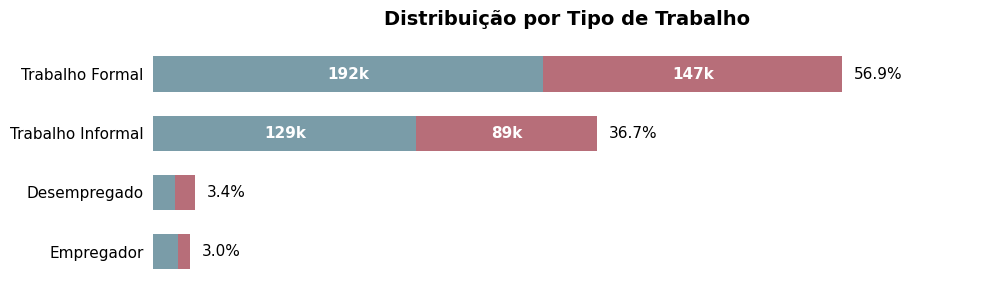

In [345]:
# Agrupamento por situacao_trabalho e sexo
df_trabalho_sexo = perfil_entrevistados.groupby(['situacao_trabalho', 'sexo'])['entrevistados'].sum().reset_index()

# Soma total por situacao_trabalho (para ordenação e percentual final)
totais_trabalho = df_trabalho_sexo.groupby('situacao_trabalho')['entrevistados'].sum().reset_index(name='total')
total_geral_trabalho = totais_trabalho['total'].sum()
totais_trabalho['percentual_total'] = totais_trabalho['total'] / total_geral_trabalho

# Mesclar total de cada situacao_trabalho de volta no df principal
df_trabalho_sexo = pd.merge(df_trabalho_sexo, totais_trabalho, on='situacao_trabalho')

# Ordenar situacao_trabalho do maior para o menor total
df_trabalho_sexo['situacao_trabalho'] = pd.Categorical(df_trabalho_sexo['situacao_trabalho'],
    categories=totais_trabalho.sort_values('total', ascending=False)['situacao_trabalho'], ordered=True)

# Mapeamento de cores (mesmo padrão)
df_trabalho_sexo['cor'] = df_trabalho_sexo['sexo'].map(cores)

# Plotagem
fig, ax = plt.subplots(figsize=(10, 3), facecolor='none')

# Lista de categorias ordenadas
situacoes = df_trabalho_sexo['situacao_trabalho'].cat.categories.tolist()

# Criar barras empilhadas horizontalmente por situacao_trabalho
for i, situacao in enumerate(situacoes):
    linha = df_trabalho_sexo[df_trabalho_sexo['situacao_trabalho'] == situacao]
    left = 0
    for _, row in linha.iterrows():
        ax.barh(i, row['entrevistados'], left=left, color=row['cor'], height=0.6)

        # Exibir valor somente se a barra for larga o suficiente
        if row['entrevistados'] > 80_000:
            valor = row['entrevistados']
            texto = f"{int(valor/1000)}k"
            ax.text(left + row['entrevistados']/2, i, texto,
                    ha='center', va='center', fontsize=11, color='white', fontweight='bold')

        left += row['entrevistados']

    # Texto percentual total ao lado da barra
    perc = linha['percentual_total'].values[0] * 100
    ax.text(left + total_geral_trabalho * 0.01, i, f"{perc:.1f}%", va='center', fontsize=11)

# Ajustes visuais
ax.set_yticks(range(len(situacoes)))
ax.set_yticklabels(situacoes, fontsize=11)
ax.set_xticks([])
ax.set_xlim(0, totais_trabalho['total'].max()*1.2)
ax.invert_yaxis()

# Limpar bordas e eixos, mantendo rótulos
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.tick_params(left=False, bottom=False)

ax.set_title("Distribuição por Tipo de Trabalho", fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.savefig('trabalho.png', transparent=True, bbox_inches='tight', dpi=600)
plt.show()

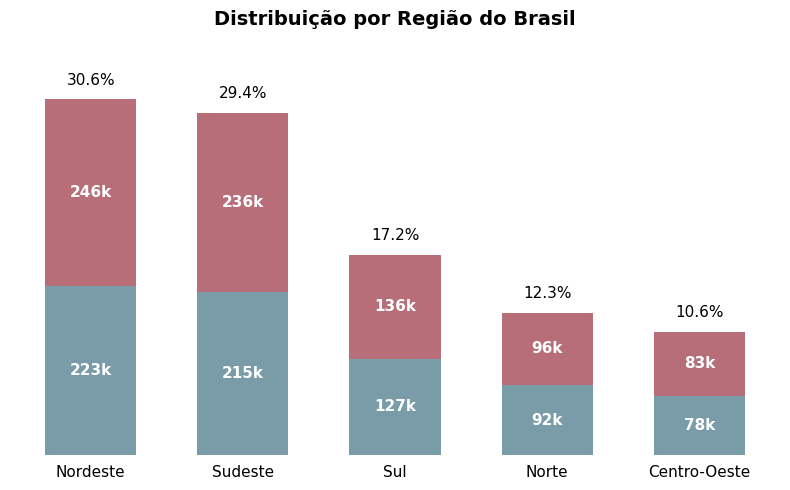

In [346]:
# Agrupamento por regiao e sexo
df_regiao_sexo = perfil_entrevistados.groupby(['regiao', 'sexo'])['entrevistados'].sum().reset_index()

# Soma total por regiao (para ordenação e percentual final)
totais_regiao = df_regiao_sexo.groupby('regiao')['entrevistados'].sum().reset_index(name='total')
total_geral = totais_regiao['total'].sum()
totais_regiao['percentual_total'] = totais_regiao['total'] / total_geral

# Mesclar total de cada regiao de volta no df principal
df_regiao_sexo = pd.merge(df_regiao_sexo, totais_regiao, on='regiao')

# Ordenar regioes do maior para o menor total
df_regiao_sexo['regiao'] = pd.Categorical(
    df_regiao_sexo['regiao'],
    categories=totais_regiao.sort_values('total', ascending=False)['regiao'],
    ordered=True
)

# Mapeamento de cores
df_regiao_sexo['cor'] = df_regiao_sexo['sexo'].map(cores)

# Plotagem
fig, ax = plt.subplots(figsize=(8, 5), facecolor='none')
ax.set_facecolor('none')

regioes = df_regiao_sexo['regiao'].cat.categories.tolist()
x = range(len(regioes))
bottoms = [0] * len(regioes)

# Plotar cada sexo, empilhando
for sexo in ['Homem', 'Mulher']:
    vals = []
    for regiao in regioes:
        linha = df_regiao_sexo[(df_regiao_sexo['regiao'] == regiao) & (df_regiao_sexo['sexo'] == sexo)]
        if not linha.empty:
            vals.append(linha['entrevistados'].values[0])
        else:
            vals.append(0)

    bars = ax.bar(x, vals, bottom=bottoms, color=cores[sexo], width=0.6, label=sexo)

    for bar, val in zip(bars, vals):
        if val > 50_000:
            texto = f"{int(val/1000)}k"
            ax.text(
                bar.get_x() + bar.get_width()/2,
                bar.get_y() + bar.get_height()/2,
                texto,
                ha='center', va='center', fontsize=11, color='white', fontweight='bold'
            )

    bottoms = [bottom + val for bottom, val in zip(bottoms, vals)]

# Texto percentual total acima da barra
for i, regiao in enumerate(regioes):
    total = totais_regiao.loc[totais_regiao['regiao'] == regiao, 'total'].values[0]
    perc = totais_regiao.loc[totais_regiao['regiao'] == regiao, 'percentual_total'].values[0] * 100
    ax.text(i, total + total_geral * 0.01, f"{perc:.1f}%", ha='center', va='bottom', fontsize=11)

# Ajustes visuais
ax.set_xticks(x)
ax.set_xticklabels(regioes, fontsize=11)
ax.set_yticks([])
ax.set_ylim(0, max(totais_regiao['total']) * 1.15)

# Limpar bordas e eixos
for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(left=False, bottom=False)
ax.set_title("Distribuição por Região do Brasil", fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.savefig('regiao.png', transparent=True, bbox_inches='tight', dpi=600)
plt.show()

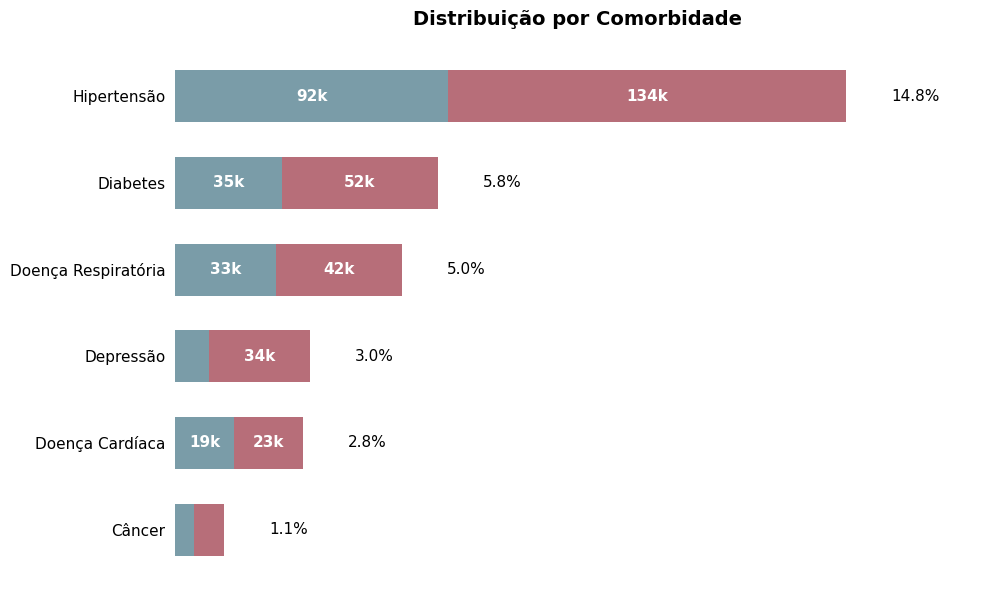

In [347]:
# Lista das colunas de comorbidades
comorbidades = ['diabetes', 'hipertensao', 'doenca_respiratoria', 'doenca_cardiaca', 'depressao', 'cancer']

# Nomes para exibição
nomes_exibicao = {
    'diabetes': 'Diabetes',
    'hipertensao': 'Hipertensão',
    'doenca_respiratoria': 'Doença Respiratória',
    'doenca_cardiaca': 'Doença Cardíaca',
    'depressao': 'Depressão',
    'cancer': 'Câncer'
}

# Armazenar dados
dados = []

# Total de entrevistados para base de cálculo
total_entrevistados = perfil_entrevistados['entrevistados'].sum()

# Processar cada comorbidade
for comorb in comorbidades:
    df_comorb = perfil_entrevistados[perfil_entrevistados[comorb] == 'Sim']
    grupo = df_comorb.groupby('sexo')['entrevistados'].sum().reset_index()
    total_comorb = grupo['entrevistados'].sum()
    percentual = total_comorb / total_entrevistados

    for _, row in grupo.iterrows():
        dados.append({
            'comorbidade': nomes_exibicao[comorb],
            'sexo': row['sexo'],
            'entrevistados': row['entrevistados'],
            'total_comorb': total_comorb,
            'percentual_total': percentual
        })

# Criar DataFrame
df_comorb = pd.DataFrame(dados)

# Ordenar com base no total
totais_comorb = df_comorb.groupby('comorbidade')['entrevistados'].sum().reset_index(name='total')
df_comorb = pd.merge(df_comorb, totais_comorb, on='comorbidade')
df_comorb['comorbidade'] = pd.Categorical(
    df_comorb['comorbidade'],
    categories=totais_comorb.sort_values('total', ascending=False)['comorbidade'],
    ordered=True
)

# Plotagem
fig, ax = plt.subplots(figsize=(10, 6), facecolor='none')

# Inverter ordem do ranking no eixo Y
comorb_ord = list(reversed(df_comorb['comorbidade'].cat.categories.tolist()))
y = range(len(comorb_ord))
lefts = [0] * len(comorb_ord)

for sexo in ['Homem', 'Mulher']:
    vals = []
    for comorb in comorb_ord:
        linha = df_comorb[(df_comorb['comorbidade'] == comorb) & (df_comorb['sexo'] == sexo)]
        if not linha.empty:
            vals.append(linha['entrevistados'].values[0])
        else:
            vals.append(0)

    bars = ax.barh(y, vals, left=lefts, color=cores[sexo], height=0.6)

    for bar, val in zip(bars, vals):
        if val > 15_000:
            texto = f"{int(val / 1000)}k"
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_y() + bar.get_height() / 2,
                    texto, ha='center', va='center', fontsize=11,
                    color='white', fontweight='bold')

    lefts = [l + v for l, v in zip(lefts, vals)]

# Percentual ao lado direito
for i, comorb in enumerate(comorb_ord):
    linha = df_comorb[df_comorb['comorbidade'] == comorb]
    perc = linha['percentual_total'].values[0] * 100
    total = linha['total'].values[0]
    ax.text(lefts[i] + total_entrevistados * 0.01, i, f"{perc:.1f}%", va='center', fontsize=11)

# Ajustes visuais
ax.set_yticks(y)
ax.set_yticklabels(comorb_ord, fontsize=11)
ax.set_xticks([])
ax.set_xlim(0, totais_comorb['total'].max() * 1.2)

for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(left=False, bottom=False)


ax.set_title("Distribuição por Comorbidade", fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.savefig("comorbidades.png", transparent=True, bbox_inches='tight', dpi=600)
plt.show()

In [348]:
testes_covid = pd.read_csv('Resposta 4.csv', sep=';')
testes_covid.head()

,tipo_teste,resultado_teste,total_resultados,total_testes,percentual
0,Exame de Sangue,Negativo,29879,41464,72.0601
1,Exame de Sangue,Positivo,11585,41464,27.9399
2,SWAB,Negativo,35798,49493,72.3294
3,SWAB,Positivo,13695,49493,27.6706
4,Teste Rápido,Negativo,53591,66701,80.3451


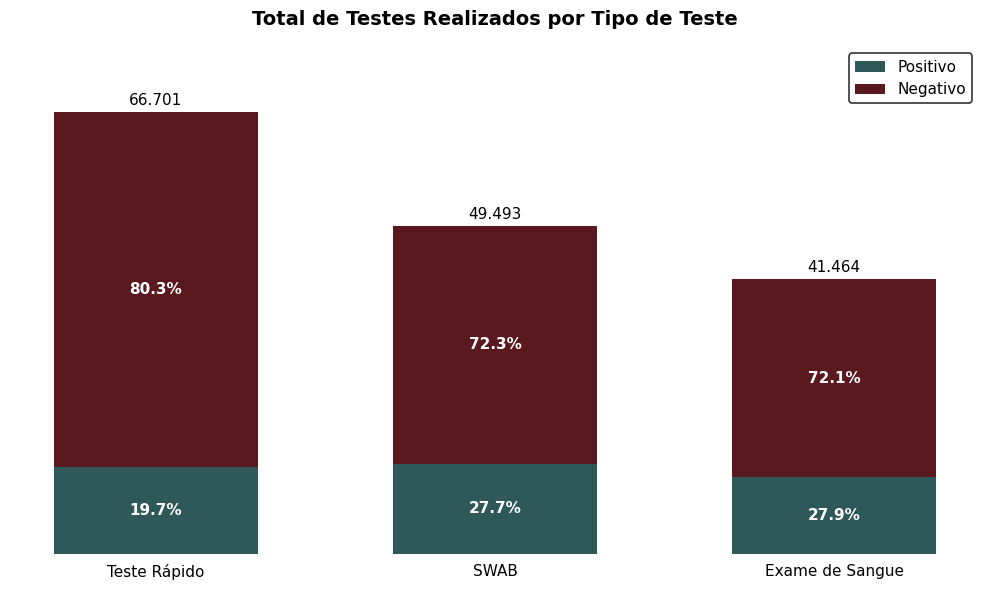

In [349]:
# Cores
cores = {
    'Positivo': '#2F5959',
    'Negativo': '#59191E'
}


# Calcular total por tipo_teste
totais = testes_covid.groupby('tipo_teste')['total_resultados'].sum().reset_index(name='total')
testes_covid = pd.merge(testes_covid, totais, on='tipo_teste')

# Ordenar tipo_teste da maior para a menor soma
testes_covid['tipo_teste'] = pd.Categorical(
    testes_covid['tipo_teste'],
    categories=totais.sort_values('total', ascending=False)['tipo_teste'],
    ordered=True
)

# Plotagem
fig, ax = plt.subplots(figsize=(10, 6), facecolor='none')

tipos = testes_covid['tipo_teste'].cat.categories.tolist()
x = range(len(tipos))
bottoms = [0] * len(tipos)

for resultado in ['Positivo', 'Negativo']:
    vals = []
    percentuais = []
    for tipo in tipos:
        linha = testes_covid[(testes_covid['tipo_teste'] == tipo) & (testes_covid['resultado_teste'] == resultado)]
        if not linha.empty:
            vals.append(linha['total_resultados'].values[0])
            percentuais.append(linha['percentual'].values[0])
        else:
            vals.append(0)
            percentuais.append(None)

    bars = ax.bar(x, vals, bottom=bottoms, color=cores.get(resultado, '#999999'), width=0.6, label=resultado)

    for bar, perc in zip(bars, percentuais):
        if perc is not None:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + bar.get_height() / 2,
                f"{perc:.1f}%",
                ha='center', va='center', fontsize=11,
                color='white', fontweight='bold'
            )

    bottoms = [b + v for b, v in zip(bottoms, vals)]

# Totais no topo
for i, tipo in enumerate(tipos):
    total = testes_covid[testes_covid['tipo_teste'] == tipo]['total_resultados'].sum()
    ax.text(i, bottoms[i] + max(bottoms) * 0.01, f"{int(total):,}".replace(',', '.'),
            ha='center', va='bottom', fontsize=11)

# Ajustes visuais
ax.set_xticks(x)
ax.set_xticklabels(tipos, fontsize=11, rotation=0)  # texto horizontal
ax.set_yticks([])
ax.set_ylim(0, max(bottoms) * 1.15)

# Legenda com borda na caixa
leg = ax.legend(frameon=True, loc='upper right', fontsize=11)
leg.get_frame().set_edgecolor('black')
leg.get_frame().set_linewidth(1.2)

for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(left=False, bottom=False)

ax.set_title("Total de Testes Realizados por Tipo de Teste", fontsize=14, weight='bold', pad=15)

plt.tight_layout()
plt.savefig("testes_covid.png", transparent=True, bbox_inches='tight', dpi=600)
plt.show()

In [350]:
# Cor única
cor = '#2F5959'

In [351]:
principais_sintomas = pd.read_csv('Resposta 5.csv', sep=';',decimal=',')
principais_sintomas.head()

,sintoma,total_positivo_com_sintoma,total_testado_com_sintoma,percentual_positivo
0,Dor de cabeça,3583,33436,10.72
1,Tosse,3112,33436,9.31
2,Febre,3093,33436,9.25
3,Dor muscular,3001,33436,8.98
4,Perda de olfato ou paladar,2832,33436,8.47


<ipython-input-352-c7b7e92ee7ca>:18: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



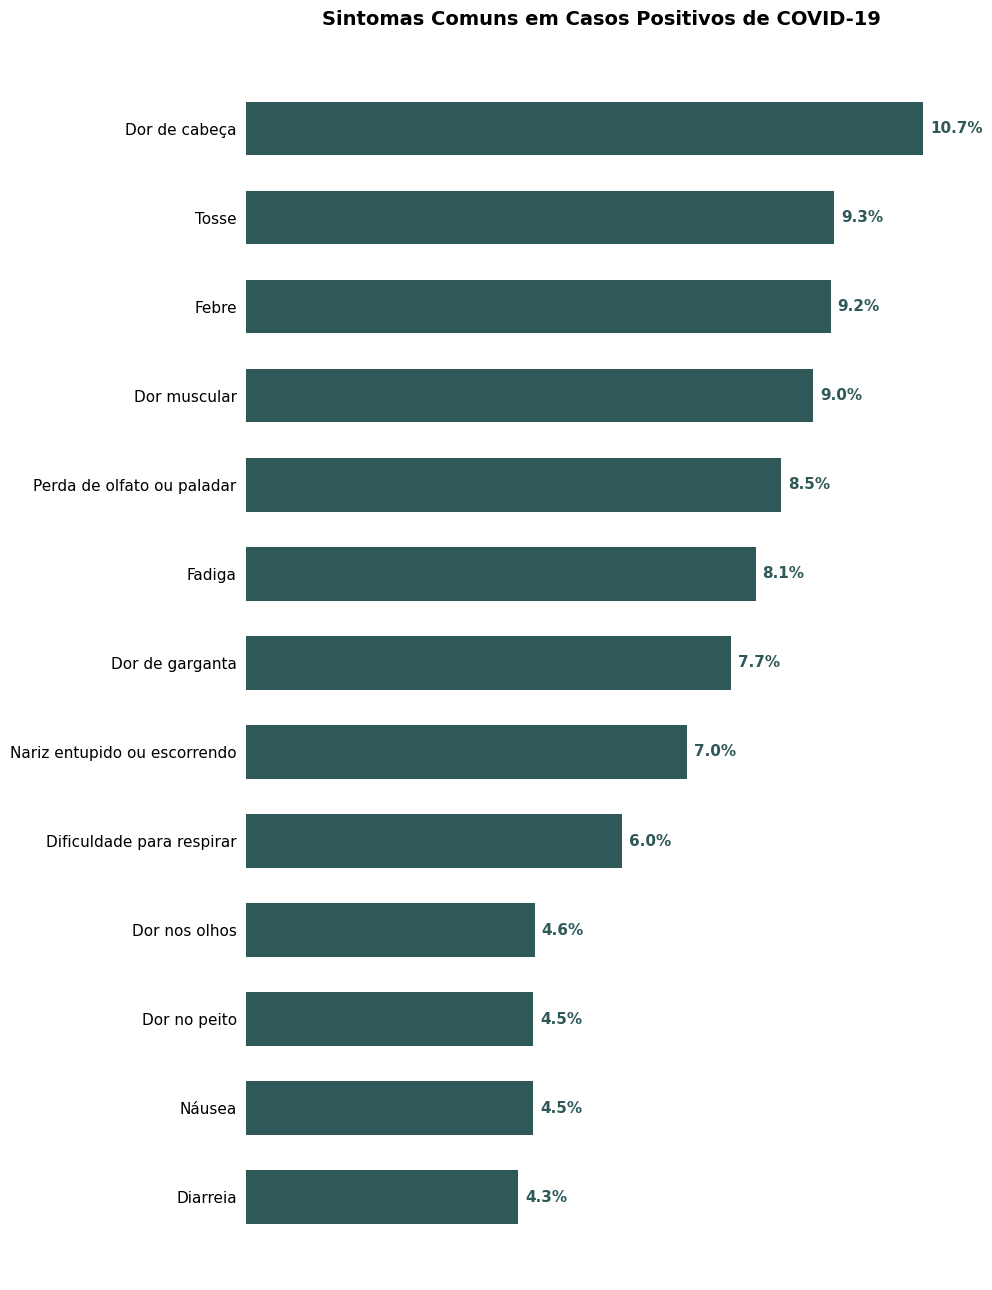

In [352]:
# Ordenar do maior para o menor pelo total_positivo_com_sintoma
principais_sintomas = principais_sintomas.sort_values('total_positivo_com_sintoma', ascending=True)  # para o ranking ficar invertido

y = principais_sintomas['sintoma']
x = principais_sintomas['total_positivo_com_sintoma']
percentual = principais_sintomas['percentual_positivo']

fig, ax = plt.subplots(figsize=(10, 13), facecolor='none')

# Barras horizontais
bars = ax.barh(y, x, color=cor, height=0.6)

# Colocar percentual ao final das barras
for i, (valor, perc) in enumerate(zip(x, percentual)):
    ax.text(valor + max(x)*0.01, i, f"{perc:.1f}%", va='center', fontsize=11, fontweight='bold', color='#2F5959')

# Ajustes visuais
ax.set_yticklabels(y, fontsize=11)
ax.set_xticks([])

# Remover bordas e ticks
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(left=False, bottom=False)

ax.set_title("Sintomas Comuns em Casos Positivos de COVID-19", fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.savefig("ranking_sintomas.png", transparent=True, bbox_inches='tight', dpi=600)
plt.show()

In [353]:
acao_tomada = pd.read_csv('Resposta 6.csv', sep=';', decimal=',')
acao_tomada.head

<bound method NDFrame.head of                                   acao  total_acao  total_acoes_tomadas  \
0                        Ficou em casa        1446                 3259   
1      Tomou remédio por conta própria         741                 3259   
2  Tomou remédio por orientação médica         581                 3259   
3           Ligou para um profissional         236                 3259   
4                Recebeu visita do SUS         164                 3259   
5                    Outra providência          46                 3259   
6            Recebeu visita particular          45                 3259   

   percentual_das_acoes  
0                 44.37  
1                 22.74  
2                 17.83  
3                  7.24  
4                  5.03  
5                  1.41  
6                  1.38  >

<ipython-input-354-7c241e6c6758>:20: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



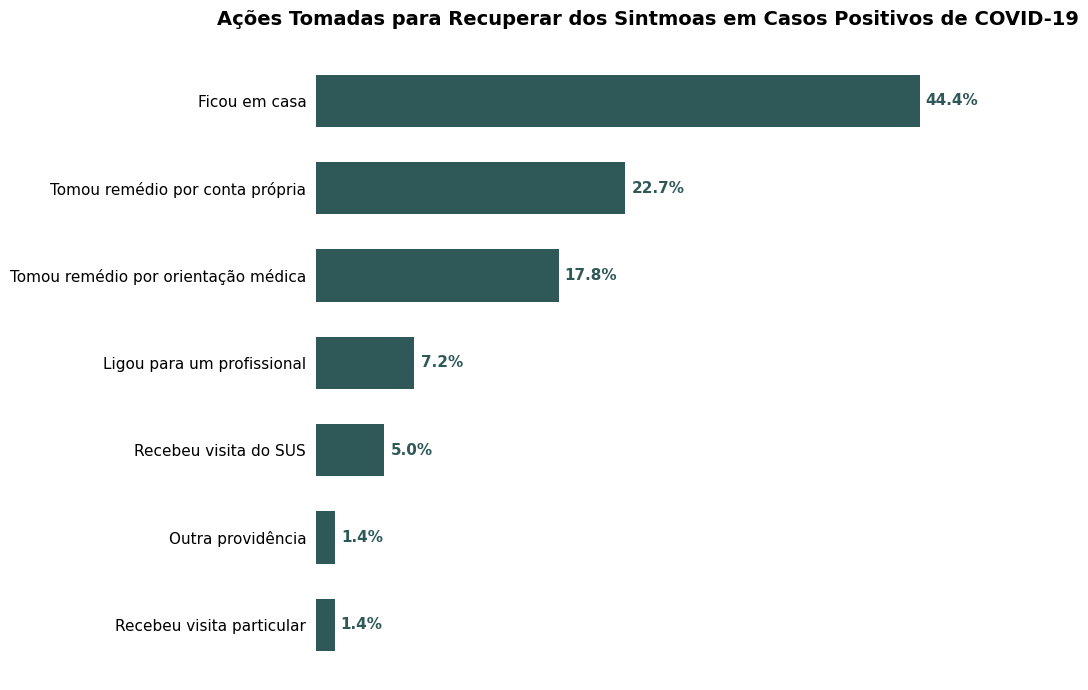

In [354]:
# Ordenar do menor para o maior para inverter ranking (maior no topo)
acao_tomada = acao_tomada.sort_values('total_acao', ascending=True)

y = acao_tomada['acao']
x = acao_tomada['total_acao']
percentual = acao_tomada['percentual_das_acoes']

cor = '#2F5959'

fig, ax = plt.subplots(figsize=(10, 7), facecolor='none')

# Barras horizontais
bars = ax.barh(y, x, color=cor, height=0.6)

# Colocar percentual ao final das barras
for i, (valor, perc) in enumerate(zip(x, percentual)):
    ax.text(valor + max(x)*0.01, i, f"{perc:.1f}%", va='center', fontsize=11, fontweight='bold', color=cor)

# Ajustes visuais
ax.set_yticklabels(y, fontsize=11)
ax.set_xticks([])
ax.set_xlim(0, max(x) * 1.1)

# Remover bordas e ticks
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(left=False, bottom=False)

ax.set_title("Ações Tomadas para Recuperar dos Sintmoas em Casos Positivos de COVID-19", fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.savefig("ranking_acao_tomada.png", transparent=True, bbox_inches='tight', dpi=600)
plt.show()


In [355]:
positividade_sintomas = pd.read_csv('Resposta 7.csv', sep=';', decimal='.')
positividade_sintomas.head()

,grupo_sintomas,resultado_teste_positivo,total_grupo,percentual
0,Sem sintomas,27416,122862,22.31
1,1 sintoma,1092,4351,25.10
2,2 sintomas,873,3001,29.09
3,3 sintomas,666,2201,30.26
4,Mais de 4 sintomas,3389,6642,51.02


In [356]:
positividade_sintomas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   grupo_sintomas            5 non-null      object 
 1   resultado_teste_positivo  5 non-null      int64  
 2   total_grupo               5 non-null      int64  
 3   percentual                5 non-null      float64
dtypes: float64(1), int64(2), object(1)
memory usage: 292.0+ bytes


<ipython-input-357-b2683c96fde7>:19: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



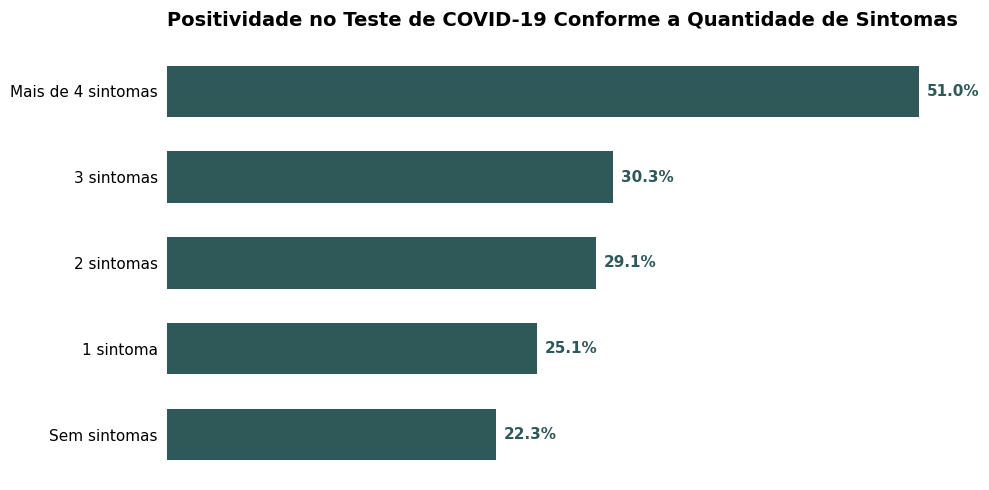

In [357]:
# Ordenar do menor para o maior percentual para o ranking invertido (maior no topo)
positividade_sintomas = positividade_sintomas.sort_values('percentual', ascending=True)

y = positividade_sintomas['grupo_sintomas']
x = positividade_sintomas['percentual']
percentual = positividade_sintomas['percentual']


fig, ax = plt.subplots(figsize=(10, 5), facecolor='none')

# Barras horizontais com comprimento proporcional ao percentual (ex: 0.6254 = 62.54%)
bars = ax.barh(y, x, color=cor, height=0.6)

# Colocar percentual ao final das barras (multiplicando por 100 para exibir em %)
for i, perc in enumerate(percentual):
    ax.text(x.iloc[i] + max(x)*0.01, i, f"{perc:.1f}%", va='center', fontsize=11, fontweight='bold', color=cor)

# Ajustes visuais
ax.set_yticklabels(y, fontsize=11)
ax.set_xticks([])

# Remover bordas e ticks
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(left=False, bottom=False)

ax.set_title("Positividade no Teste de COVID-19 Conforme a Quantidade de Sintomas", fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.savefig("ranking_positividade_sintomas.png", transparent=True, bbox_inches='tight', dpi=600)
plt.show()

In [358]:
pacientes_entubados = pd.read_csv('Resposta 8.csv', sep=';', decimal='.')
pacientes_entubados.head()

,acao,total_entrevistados
0,Procurou estabelecimento de saúde,4166
1,Precisou ser internado,415
2,Precisou ser entubado,146


In [359]:
acoes = pacientes_entubados['acao'].tolist()
valores = pacientes_entubados['total_entrevistados'].tolist()

total_topo = max(valores)
percentuais = [v / total_topo * 100 for v in valores]

# Texto só com valor
textos = [f"{v}" for v in valores]

fig = go.Figure(go.Funnel(
    y=acoes,
    x=valores,
    textinfo="text+percent initial",  # valor + percentual relativo ao topo
    text=textos,
    marker={"color": "#2F5959"},
    opacity=1.0
))

fig.update_layout(
    title={
        'text': "Procurou Atendimento Após Teste Positivo para COVID-19",
        'font': {'size': 14, 'family': 'Arial', 'color': 'black', 'weight': 'bold'},
        'x': 0.5,          # centraliza horizontalmente (0 = esquerda, 1 = direita)
        'xanchor': 'center',
        'yanchor': 'top',
        'pad': {'b': 15}   # padding em pixels abaixo do título
    },
    width=960,
    height=288,
    plot_bgcolor='rgba(0,0,0,0)',
    paper_bgcolor='rgba(0,0,0,0)',
    margin=dict(l=20, r=20, t=40, b=20)
)
fig.write_image("pacientes_internados.png", scale=3, engine="kaleido")
fig.show()


In [360]:
possui_plano = pd.read_csv('Resposta 9.csv', sep=';')
possui_plano['data'] = pd.to_datetime(possui_plano['data'])
possui_plano.head()

,data,total_com_plano
0,2020-07-07,21367
1,2020-07-14,21946
2,2020-07-21,21859
3,2020-07-28,21705
4,2020-08-07,20766


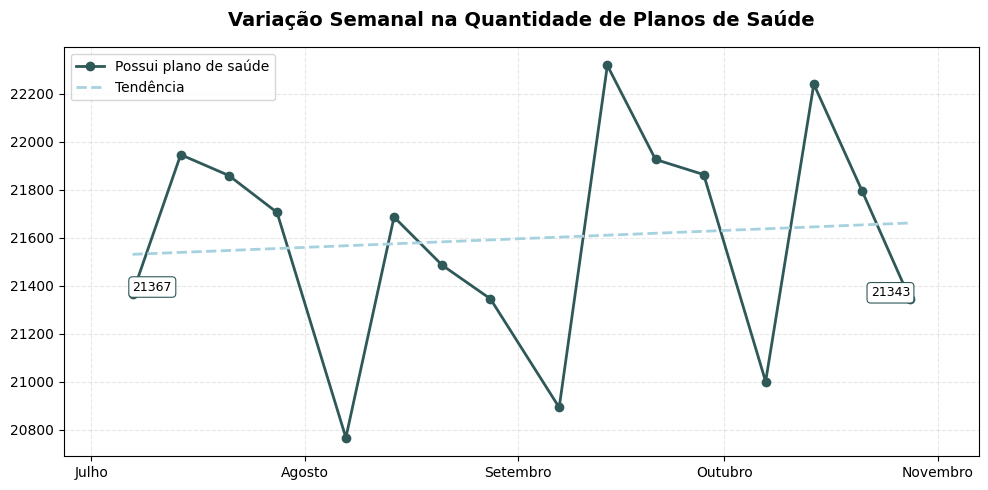

In [361]:
# Define o limite inicial do eixo x como o primeiro dia do mês da menor data do dataframe
data_inicio = possui_plano['data'].min() - pd.Timedelta(days=10)

# Define o limite final do eixo x como o último dia do mês da maior data do dataframe
data_fim = possui_plano['data'].max() + pd.Timedelta(days=10)

# Cria a figura e o eixo para o gráfico com tamanho 10x5 polegadas e fundo transparente
fig, ax = plt.subplots(figsize=(10, 5), facecolor='none')

# Plota a série de pontos com marcadores circulares, cor especificada e linha de espessura 2
ax.plot(
    possui_plano['data'],               # eixo x com as datas
    possui_plano['total_com_plano'],   # eixo y com os valores totais
    marker='o',                        # marcador circular nos pontos
    color='#2F5959',                   # cor das linhas e marcadores
    linewidth=2,                      # espessura da linha
    label='Possui plano de saúde'     # legenda para a série
)

# Adiciona rótulo no primeiro e último ponto
primeira_data = possui_plano['data'].iloc[0]
ultimo_dado = possui_plano['data'].iloc[-1]

primeiro_valor = possui_plano['total_com_plano'].iloc[0]
ultimo_valor = possui_plano['total_com_plano'].iloc[-1]

# Estilo da caixa
caixa_estilo = dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#2F5959', linewidth=0.8)
ax.text(primeira_data, primeiro_valor, f'{primeiro_valor}', va='bottom', ha='left', fontsize=9, bbox=caixa_estilo)
ax.text(ultimo_dado, ultimo_valor, f'{ultimo_valor}', va='bottom', ha='right', fontsize=9, bbox=caixa_estilo)

# Define os limites do eixo x para mostrar desde o início do primeiro mês até o fim do último mês
ax.set_xlim(data_inicio, data_fim)

# Define que o eixo x terá uma marcação principal por mês
ax.xaxis.set_major_locator(mdates.MonthLocator())

# Função para formatar os rótulos do eixo x para nomes de meses em português
def formatador_portugues(x, pos=None):
    dt = mdates.num2date(x)                  # converte número do eixo para objeto datetime
    return meses_pt.get(dt.month, '')        # retorna o nome do mês em português, ou vazio se não achar

# Aplica o formatador personalizado ao eixo x
ax.xaxis.set_major_formatter(plt.FuncFormatter(formatador_portugues))

# Prepara os dados para ajuste de linha de tendência

# Converte as datas para números float, necessário para regressão numérica
x_nums = mdates.date2num(possui_plano['data'])

# Valores y para regressão
y = possui_plano['total_com_plano']

# Ajuste linear (polinômio de grau 1) nos dados x e y
coef = np.polyfit(x_nums, y, 1)

# Cria uma função polinomial com os coeficientes encontrados
poly1d_fn = np.poly1d(coef)

# Plota a linha de tendência com cor clara, linha tracejada e legenda
ax.plot(possui_plano['data'], poly1d_fn(x_nums), color='#A6D1DF', linestyle='--', linewidth=2, label='Tendência')

# Torna as bordas da área do gráfico visíveis
for spine in ax.spines.values():
    spine.set_visible(True)

# Adiciona grid pontilhado em ambos os eixos x e y com transparência 30%
ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.grid(axis='y', linestyle='--', alpha=0.3)

# Ajusta rotação e tamanho das labels do eixo x e y
ax.tick_params(axis='x', rotation=0)
ax.tick_params(axis='y', labelsize=10)

# Mostra a legenda do gráfico
ax.legend()
ax.set_title("Variação Semanal na Quantidade de Planos de Saúde", fontsize=14, weight='bold', pad=15)

# Ajusta layout para evitar cortes e sobreposições
plt.tight_layout()

# Salva o gráfico em PNG com fundo transparente, bordas ajustadas e alta resolução
plt.savefig("evolução_plano_de_saude.png", transparent=True, bbox_inches='tight', dpi=600)


# Exibe o gráfico
plt.show()


In [362]:
media_salarial = pd.read_csv('Resposta 10.csv', sep=';', decimal=',')
media_salarial['data'] = pd.to_datetime(media_salarial['data'])
media_salarial.head()

,data,media_salarial
0,2020-07-07,1907.728517
1,2020-07-14,1952.061453
2,2020-07-21,1997.755675
3,2020-07-28,1998.988713
4,2020-08-07,1991.315848


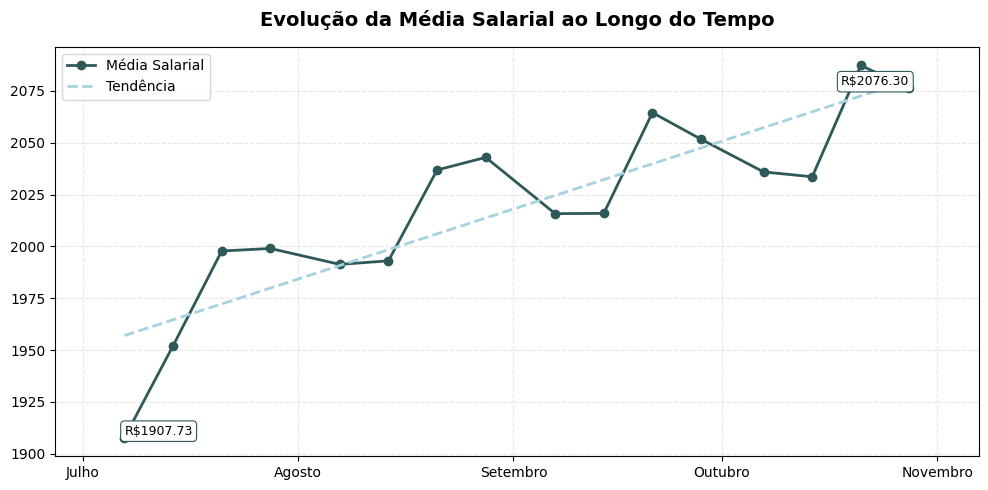

In [363]:
# Define o limite inicial do eixo x como o primeiro dia do mês da menor data do dataframe
data_inicio = media_salarial['data'].min() - pd.Timedelta(days=10)

# Define o limite final do eixo x como o último dia do mês da maior data do dataframe
data_fim = media_salarial['data'].max() + pd.Timedelta(days=10)

# Cria a figura e o eixo para o gráfico com tamanho 10x5 polegadas e fundo transparente
fig, ax = plt.subplots(figsize=(10, 5), facecolor='none')

# Plota a série de pontos com marcadores circulares, cor especificada e linha de espessura 2
ax.plot(
    media_salarial['data'],        # eixo x com as datas
    media_salarial['media_salarial'],  # eixo y com os valores da média salarial
    marker='o',                   # marcador circular nos pontos
    color='#2F5959',              # cor das linhas e marcadores
    linewidth=2,                  # espessura da linha
    label='Média Salarial'        # legenda para a série
)

# Adiciona rótulo no primeiro e último ponto
primeira_data = media_salarial['data'].iloc[0]
ultimo_dado = media_salarial['data'].iloc[-1]

primeiro_valor = media_salarial['media_salarial'].iloc[0]
ultimo_valor = media_salarial['media_salarial'].iloc[-1]

# Estilo da caixa
caixa_estilo = dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#2F5959', linewidth=0.8)
ax.text(primeira_data, primeiro_valor, f'R${primeiro_valor:.2f}', va='bottom', ha='left', fontsize=9, bbox=caixa_estilo)
ax.text(ultimo_dado, ultimo_valor, f'R${ultimo_valor:.2f}', va='bottom', ha='right', fontsize=9, bbox=caixa_estilo)

# Define os limites do eixo x para mostrar desde o início do primeiro mês até o fim do último mês
ax.set_xlim(data_inicio, data_fim)

# Define que o eixo x terá uma marcação principal por mês
ax.xaxis.set_major_locator(mdates.MonthLocator())

# Função para formatar os rótulos do eixo x para nomes de meses em português
def formatador_portugues(x, pos=None):
    dt = mdates.num2date(x)                  # converte número do eixo para objeto datetime
    return meses_pt.get(dt.month, '')        # retorna o nome do mês em português, ou vazio se não achar

# Aplica o formatador personalizado ao eixo x
ax.xaxis.set_major_formatter(plt.FuncFormatter(formatador_portugues))

# Prepara os dados para ajuste de linha de tendência

# Converte as datas para números float, necessário para regressão numérica
x_nums = mdates.date2num(media_salarial['data'])

# Valores y para regressão
y = media_salarial['media_salarial']

# Ajuste linear (polinômio de grau 1) nos dados x e y
coef = np.polyfit(x_nums, y, 1)

# Cria uma função polinomial com os coeficientes encontrados
poly1d_fn = np.poly1d(coef)

# Plota a linha de tendência com cor clara, linha tracejada e legenda
ax.plot(media_salarial['data'], poly1d_fn(x_nums), color='#A6D1DF', linestyle='--', linewidth=2, label='Tendência')

# Torna as bordas da área do gráfico visíveis
for spine in ax.spines.values():
    spine.set_visible(True)

# Adiciona grid pontilhado em ambos os eixos x e y com transparência 30%
ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.grid(axis='y', linestyle='--', alpha=0.3)

# Ajusta rotação e tamanho das labels do eixo x e y
ax.tick_params(axis='x', rotation=0)
ax.tick_params(axis='y', labelsize=10)

# Mostra a legenda do gráfico
ax.legend()
ax.set_title("Evolução da Média Salarial ao Longo do Tempo", fontsize=14, weight='bold', pad=15)

# Ajusta layout para evitar cortes e sobreposições
plt.tight_layout()

# Salva o gráfico em PNG com fundo transparente, bordas ajustadas e alta resolução
plt.savefig("evolucao_media_salarial.png", transparent=True, bbox_inches='tight', dpi=600)


# Exibe o gráfico
plt.show()

In [364]:
trabalhou_semana_passada = pd.read_csv('Resposta 11.csv', sep=';')
trabalhou_semana_passada['data'] = pd.to_datetime(trabalhou_semana_passada['data'])
trabalhou_semana_passada.head()

,data,trabalhou
0,2020-07-07,31518
1,2020-07-14,32278
2,2020-07-21,32971
3,2020-07-28,33064
4,2020-08-07,33390


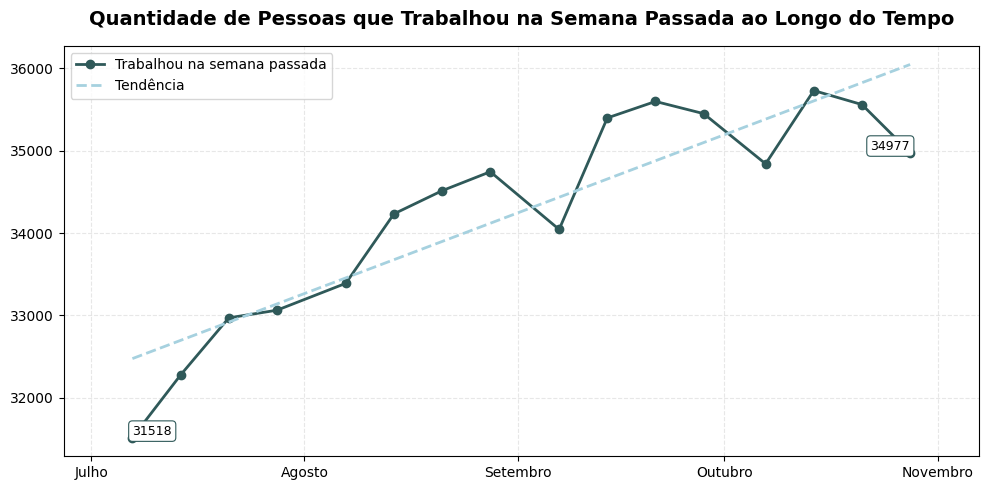

In [365]:
# Define o limite inicial do eixo x como o primeiro dia do mês da menor data do dataframe
data_inicio = trabalhou_semana_passada['data'].min() - pd.Timedelta(days=10)

# Define o limite final do eixo x como o último dia do mês da maior data do dataframe
data_fim = trabalhou_semana_passada['data'].max() + pd.Timedelta(days=10)

# Cria a figura e o eixo para o gráfico com tamanho 10x5 polegadas e fundo transparente
fig, ax = plt.subplots(figsize=(10, 5), facecolor='none')

# Plota a série de pontos com marcadores circulares, cor especificada e linha de espessura 2
ax.plot(
    trabalhou_semana_passada['data'],               # eixo x com as datas
    trabalhou_semana_passada['trabalhou'],   # eixo y com os valores totais
    marker='o',                        # marcador circular nos pontos
    color='#2F5959',                   # cor das linhas e marcadores
    linewidth=2,                      # espessura da linha
    label='Trabalhou na semana passada'     # legenda para a série
)

# Adiciona rótulo no primeiro e último ponto
primeira_data = trabalhou_semana_passada['data'].iloc[0]
ultimo_dado = trabalhou_semana_passada['data'].iloc[-1]

primeiro_valor = trabalhou_semana_passada['trabalhou'].iloc[0]
ultimo_valor = trabalhou_semana_passada['trabalhou'].iloc[-1]

# Estilo da caixa
caixa_estilo = dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#2F5959', linewidth=0.8)
ax.text(primeira_data, primeiro_valor, f'{primeiro_valor}', va='bottom', ha='left', fontsize=9, bbox=caixa_estilo)
ax.text(ultimo_dado, ultimo_valor, f'{ultimo_valor}', va='bottom', ha='right', fontsize=9, bbox=caixa_estilo)

# Define os limites do eixo x para mostrar desde o início do primeiro mês até o fim do último mês
ax.set_xlim(data_inicio, data_fim)

# Define que o eixo x terá uma marcação principal por mês
ax.xaxis.set_major_locator(mdates.MonthLocator())

# Função para formatar os rótulos do eixo x para nomes de meses em português
def formatador_portugues(x, pos=None):
    dt = mdates.num2date(x)                  # converte número do eixo para objeto datetime
    return meses_pt.get(dt.month, '')        # retorna o nome do mês em português, ou vazio se não achar

# Aplica o formatador personalizado ao eixo x
ax.xaxis.set_major_formatter(plt.FuncFormatter(formatador_portugues))

# Prepara os dados para ajuste de linha de tendência

# Converte as datas para números float, necessário para regressão numérica
x_nums = mdates.date2num(trabalhou_semana_passada['data'])

# Valores y para regressão
y = trabalhou_semana_passada['trabalhou']

# Ajuste linear (polinômio de grau 1) nos dados x e y
coef = np.polyfit(x_nums, y, 1)

# Cria uma função polinomial com os coeficientes encontrados
poly1d_fn = np.poly1d(coef)

# Plota a linha de tendência com cor clara, linha tracejada e legenda
ax.plot(trabalhou_semana_passada['data'], poly1d_fn(x_nums), color='#A6D1DF', linestyle='--', linewidth=2, label='Tendência')

# Torna as bordas da área do gráfico visíveis
for spine in ax.spines.values():
    spine.set_visible(True)

# Adiciona grid pontilhado em ambos os eixos x e y com transparência 30%
ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.grid(axis='y', linestyle='--', alpha=0.3)

# Ajusta rotação e tamanho das labels do eixo x e y
ax.tick_params(axis='x', rotation=0)
ax.tick_params(axis='y', labelsize=10)

# Mostra a legenda do gráfico
ax.legend()
ax.set_title("Quantidade de Pessoas que Trabalhou na Semana Passada ao Longo do Tempo", fontsize=14, weight='bold', pad=15)

# Ajusta layout para evitar cortes e sobreposições
plt.tight_layout()

# Salva o gráfico em PNG com fundo transparente, bordas ajustadas e alta resolução
plt.savefig("evolucao_trabalhou_semana_passada.png", transparent=True, bbox_inches='tight', dpi=600)


# Exibe o gráfico
plt.show()

In [366]:
comportamento_populacao = pd.read_csv('Resposta 12.csv', sep=';')
comportamento_populacao['data'] = pd.to_datetime(comportamento_populacao['data'])
comportamento_populacao.head()

,data,restricao_covid,total_entrevistados
0,2020-07-07,Ficou rigorosamente em casa,21055
1,2020-07-07,Não fez restrição,2318
2,2020-07-07,"Reduziu o contato com as pessoas, mas continuo...",26146
3,2020-07-07,Só saiu de casa em caso de necessidade básica,43782
4,2020-07-14,Ficou rigorosamente em casa,23312


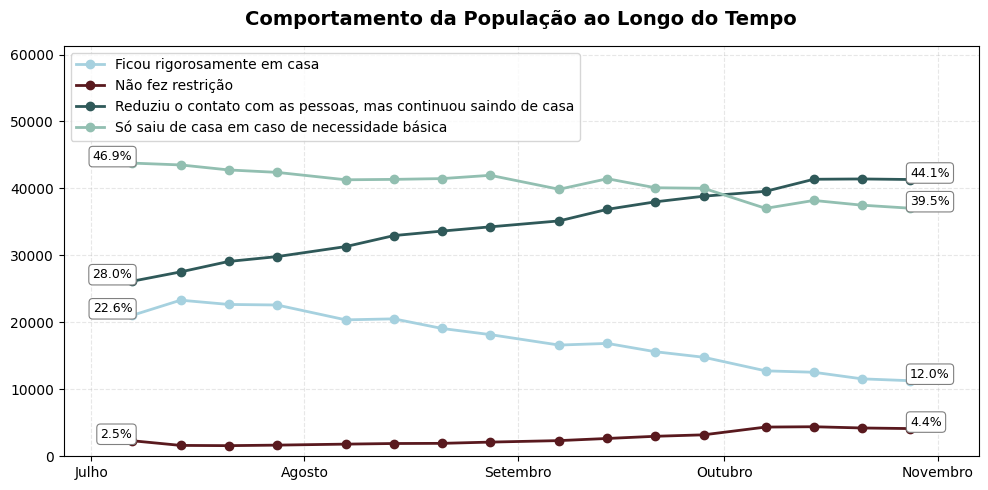

In [367]:
# Paleta de cores personalizada para cada categoria de restrição COVID
cores_personalizadas = {
    'Ficou rigorosamente em casa': '#A6D1DF',
    'Não fez restrição': '#59191E',
    'Reduziu o contato com as pessoas, mas continuou saindo de casa': '#2F5959',
    'Só saiu de casa em caso de necessidade básica': '#92BFB1'
}

# Calcula total geral entrevistados por data para calcular percentual
total_por_data = comportamento_populacao.groupby('data')['total_entrevistados'].sum()

# Define os limites do eixo x
data_inicio = comportamento_populacao['data'].min() - pd.Timedelta(days=10)
data_fim = comportamento_populacao['data'].max() + pd.Timedelta(days=10)

# Limite superior do eixo Y
ymax = comportamento_populacao['total_entrevistados'].max() * 1.4

fig, ax = plt.subplots(figsize=(10, 5), facecolor='none')

# Define o estilo da caixa de fundo dos rótulos
caixa_estilo = dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='gray', linewidth=0.8)

# Define o estilo da caixa de fundo dos rótulos
caixa_estilo = dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='gray', linewidth=0.8)

for categoria, grupo in comportamento_populacao.groupby('restricao_covid'):
    grupo = grupo.sort_values('data')

    ax.plot(
        grupo['data'],
        grupo['total_entrevistados'],
        marker='o',
        color=cores_personalizadas.get(categoria, '#000000'),
        linewidth=2,
        label=categoria
    )

    percentuais = grupo.apply(lambda row: 100 * row['total_entrevistados'] / total_por_data.loc[row['data']], axis=1)

    # Primeiro ponto com caixa
    x_first = grupo['data'].iloc[0]
    y_first = grupo['total_entrevistados'].iloc[0]
    perc_first = percentuais.iloc[0]
    ax.text(
        x_first, y_first, f"{perc_first:.1f}%",
        fontsize=9,
        color='black',  # texto preto
        va='bottom', ha='right',
        bbox=caixa_estilo
    )

    # Último ponto com caixa
    x_last = grupo['data'].iloc[-1]
    y_last = grupo['total_entrevistados'].iloc[-1]
    perc_last = percentuais.iloc[-1]
    ax.text(
        x_last, y_last, f"{perc_last:.1f}%",
        fontsize=9,
        color='black',  # texto preto
        va='bottom', ha='left',
        bbox=caixa_estilo
    )

# Limites dos eixos
ax.set_xlim(data_inicio, data_fim)
ax.set_ylim(0, ymax)

# Marcação eixo x por mês
ax.xaxis.set_major_locator(mdates.MonthLocator())

# Formatação dos rótulos do eixo x em português
def formatador_portugues(x, pos=None):
    dt = mdates.num2date(x)
    return meses_pt.get(dt.month, '')

ax.xaxis.set_major_formatter(plt.FuncFormatter(formatador_portugues))

for spine in ax.spines.values():
    spine.set_visible(True)

ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.grid(axis='y', linestyle='--', alpha=0.3)

ax.tick_params(axis='x', rotation=0)
ax.tick_params(axis='y', labelsize=10)

ax.legend(loc='upper left')
ax.set_title("Comportamento da População ao Longo do Tempo", fontsize=14, weight='bold', pad=15)

plt.tight_layout()
plt.savefig("evolucao_comportamento_populacao.png", transparent=True, bbox_inches='tight', dpi=600)
plt.show()